In [37]:
import pandas as pd
from rapidfuzz import fuzz
from collections import defaultdict
import json
from pathlib import Path
from tqdm.cli import tqdm
from matplotlib import pyplot as plt
import seaborn as sns

In [38]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))

In [39]:
from src.duplicate_page_discovery import DuplicateConfig
from src.book_overlap_visualizations import (
    migration_duplicate_filtering_before_after_counts,
    plot_book_year_event_heatmap,
    plot_migration_similarity_heatmaps,
    plot_non_duplicate_migration_histogram,
)

In [40]:
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

## Examining specific years from a parish

{'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_ap': {'before': 1923,
  'after': 1923},
 'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_tk636': {'before': 1639,
  'after': 798}}

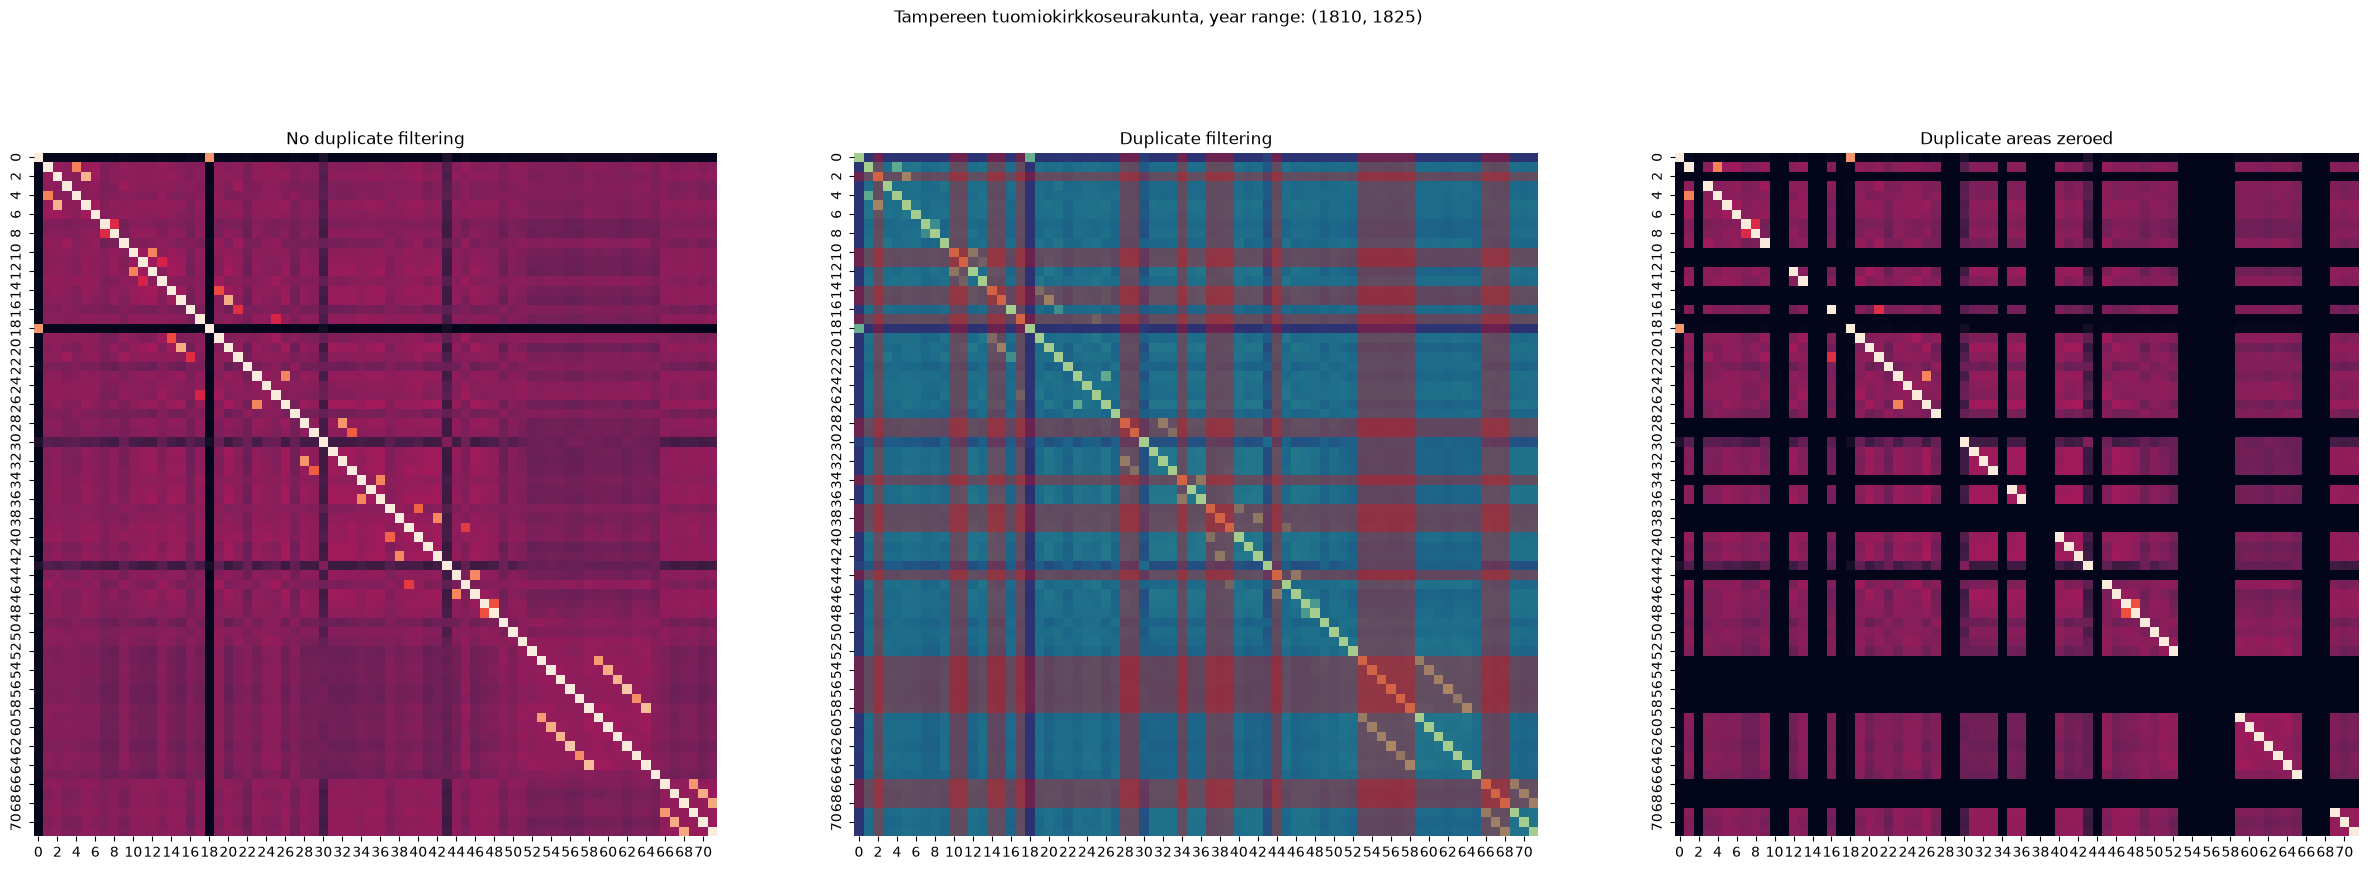

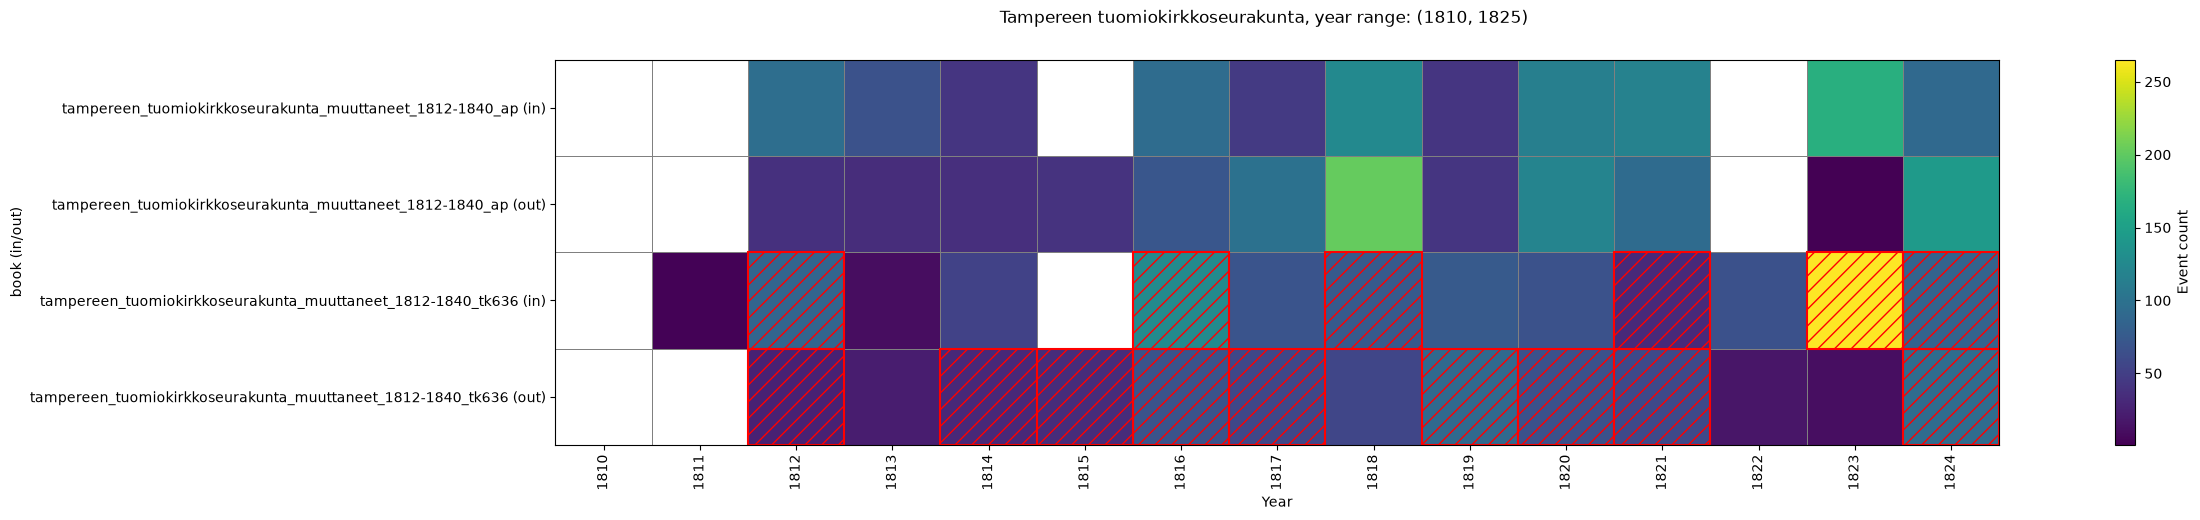

In [41]:
df_tampereen_tuom = pd.read_json(
    outputs_dir/f"json/all_migration_events_parish_splits_duplicate_info/543_migration_events.jsonl",
    lines=True,
)
fig, axs = plot_migration_similarity_heatmaps(
    df_tampereen_tuom,
    "Tampereen tuomiokirkkoseurakunta",
    (1810, 1825),
    scorer=fuzz.ratio,
    vmax=100.0,
)
fig, axs = plot_book_year_event_heatmap(
    df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1810, 1825)
)
migration_duplicate_filtering_before_after_counts(
    df_tampereen_tuom, (1810, 1825)
)

## Examining whole history of a parish

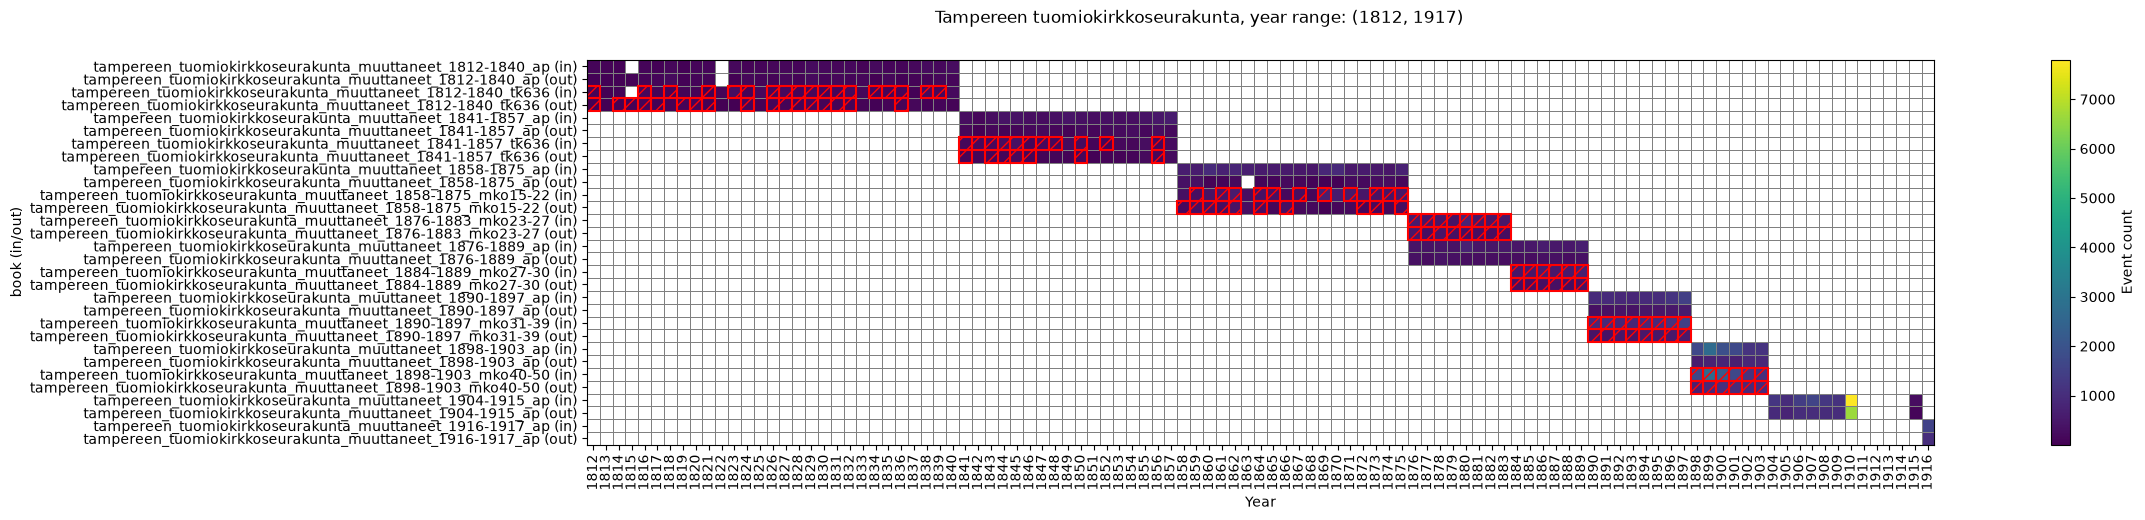

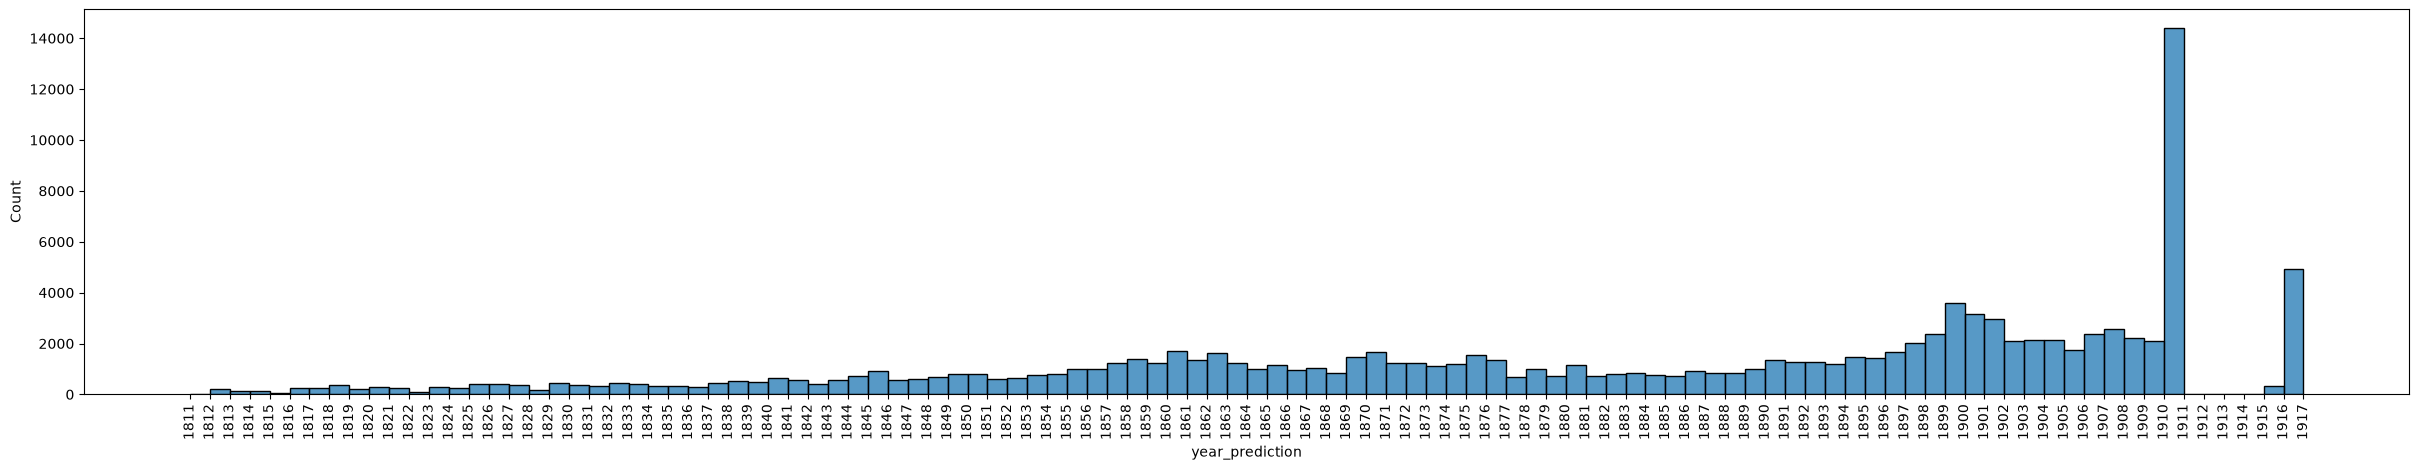

In [42]:
fig, axs = plot_book_year_event_heatmap(df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1812, 1917))
plot_non_duplicate_migration_histogram(df_tampereen_tuom)

## Overall counts of pages

In [43]:
MIN_INFO_ROWS = 0
valid_years = (1600, 1980)

output_jsonls = list(Path(
    outputs_dir/"json/all_migration_events_parish_splits_duplicate_info"
).glob("*.jsonl"))

page_records: dict[tuple, dict] = {}

In [ ]:
for file_path in tqdm(output_jsonls):
    with open(file_path) as fp:
        for line in fp:
            e = json.loads(line)
            page_key = (e["book"], e["page_n"], e["side"])
            if page_key not in page_records:
                page_records[page_key] = {
                    "duplicate": e["duplicate"],
                    "in_out": e["in/out"],
                    "year": e["year_prediction"],
                    "info_count": 0,
                }
            if e["has_information"]:
                page_records[page_key]["info_count"] += 1

100%|██████████| 468/468 [00:38<00:00, 12.14it/s]


In [45]:
counts = defaultdict(int)
year_counts = {
    k: defaultdict(int)
    for k in [
        "all",
        "all_valid_year",
        "non_dup",
        "non_dup_clear",
        "non_dup_info",
        "non_dup_clear_info"
    ]
}

for page in page_records.values():
    has_info = page["info_count"] >= MIN_INFO_ROWS
    is_dup = page["duplicate"]
    year = page["year"]
    valid_year = year in range(*valid_years)
    clear = page["in_out"] in ("in", "out") and valid_year

    counts["total"] += 1
    counts["total_info"] += has_info

    year_counts["all"][year] += 1
    if valid_year:
        year_counts["all_valid_year"][year] += 1
    if not is_dup:
        counts["non_dup"] += 1
        counts["non_dup_info"] += has_info
        if valid_year:
            year_counts["non_dup"][year] += 1
            year_counts["non_dup_info"][year] += has_info
        if clear:
            counts["non_dup_clear"] += 1
            counts["non_dup_clear_info"] += has_info
            year_counts["non_dup_clear"][year] += 1
            year_counts["non_dup_clear_info"][year] += has_info

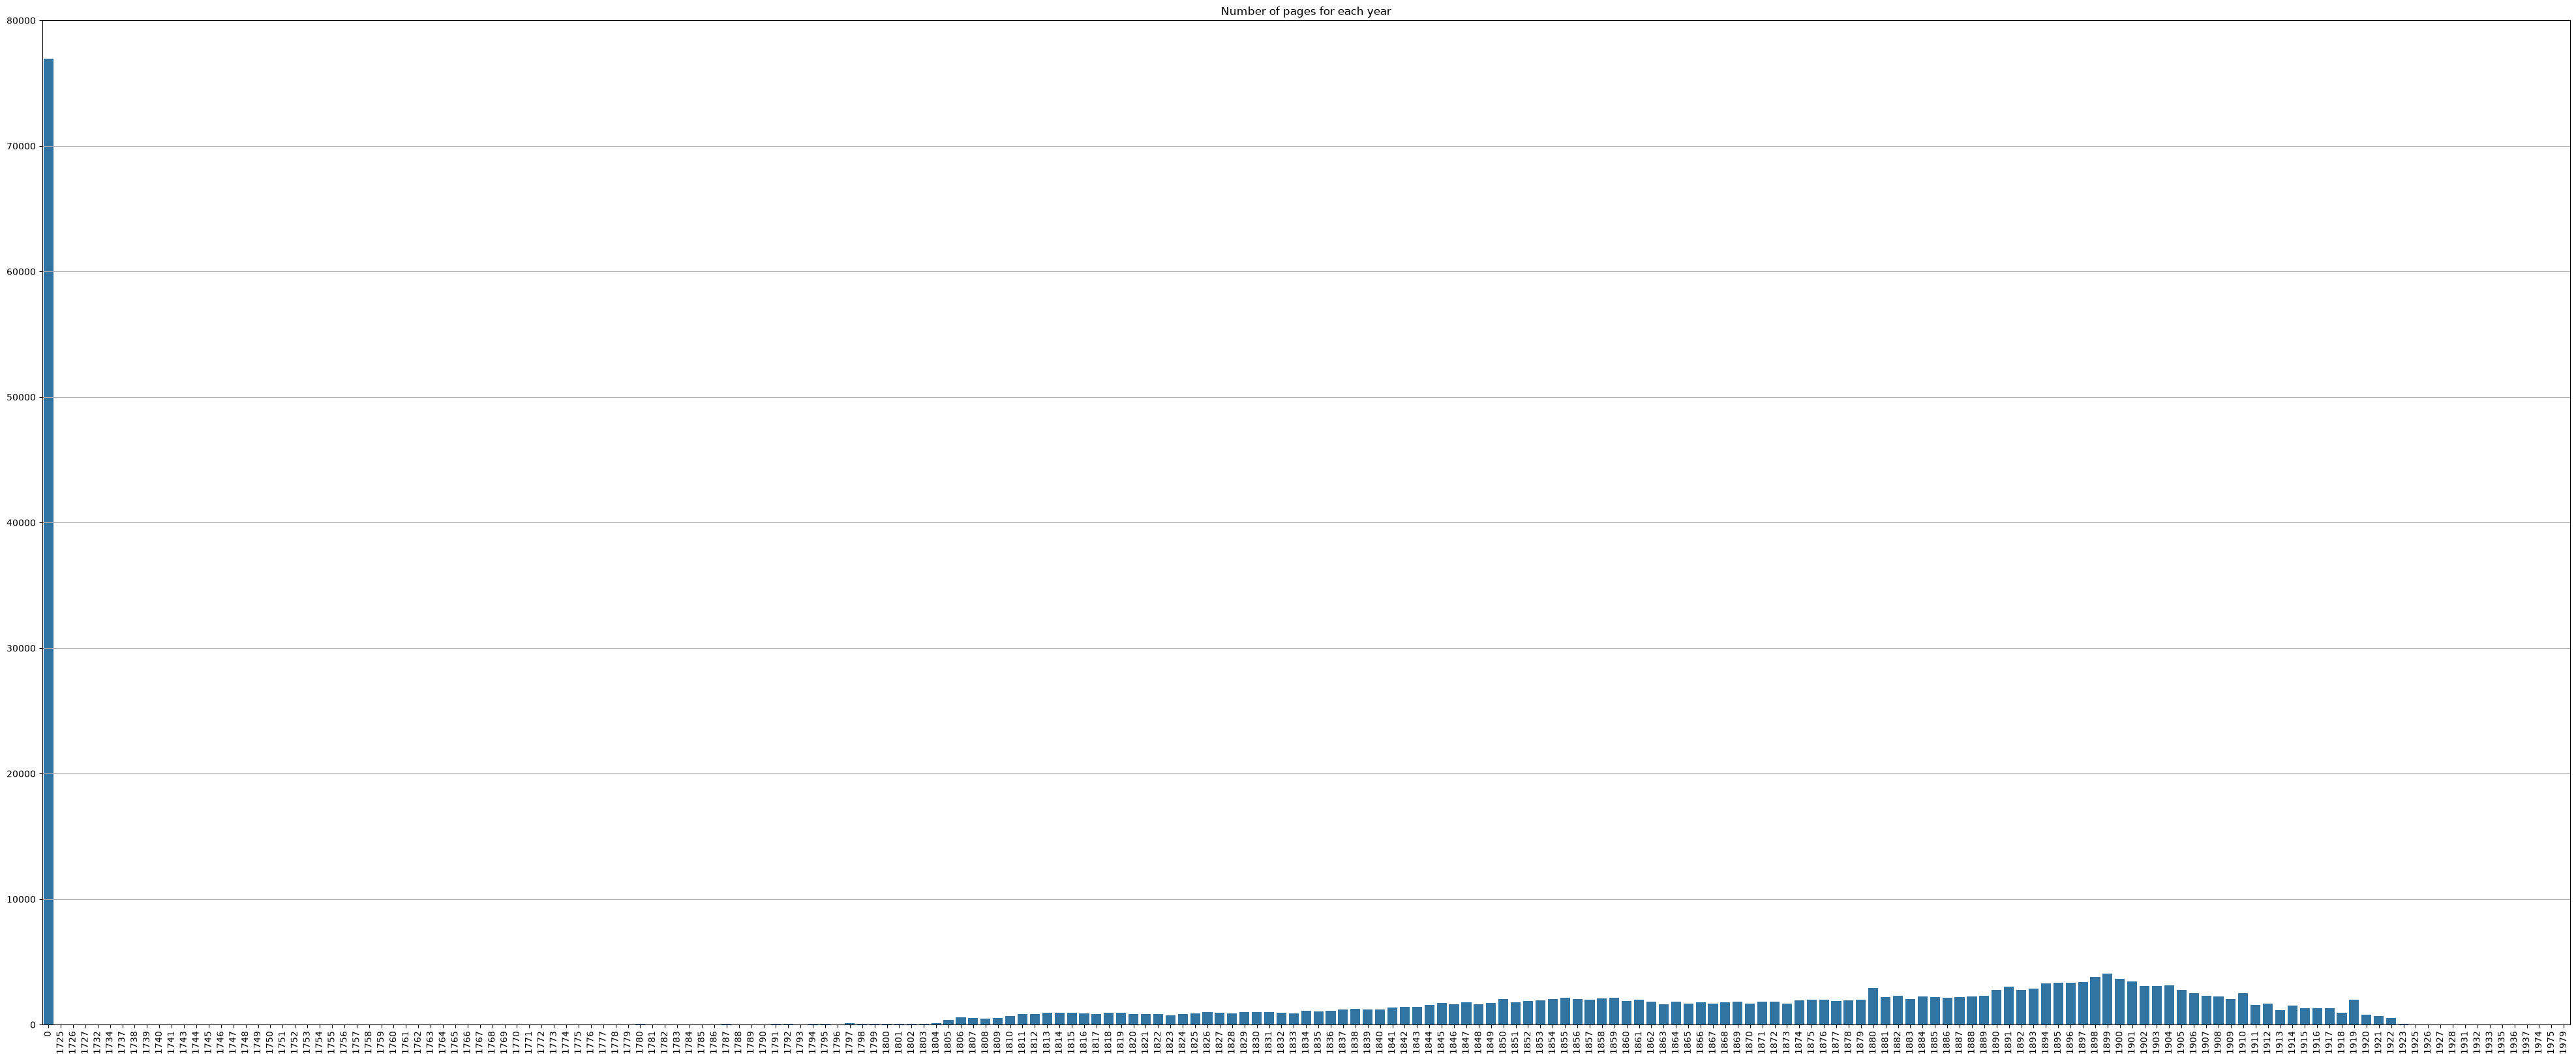

In [81]:
year_start = min(year_counts["all"].keys())
year_end = max(year_counts["all"].keys())

fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["all"].items()]),
    y=tuple([x[1] for x in year_counts["all"].items()]),
)
axs.set_ylim(0, 80000)
axs.grid(axis="y")
axs.set_title("Number of pages for each year")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["all"].keys()), rotation=90)

In [47]:
year_start = min(year_counts["all_valid_year"].keys())
year_end = max(year_counts["all_valid_year"].keys())

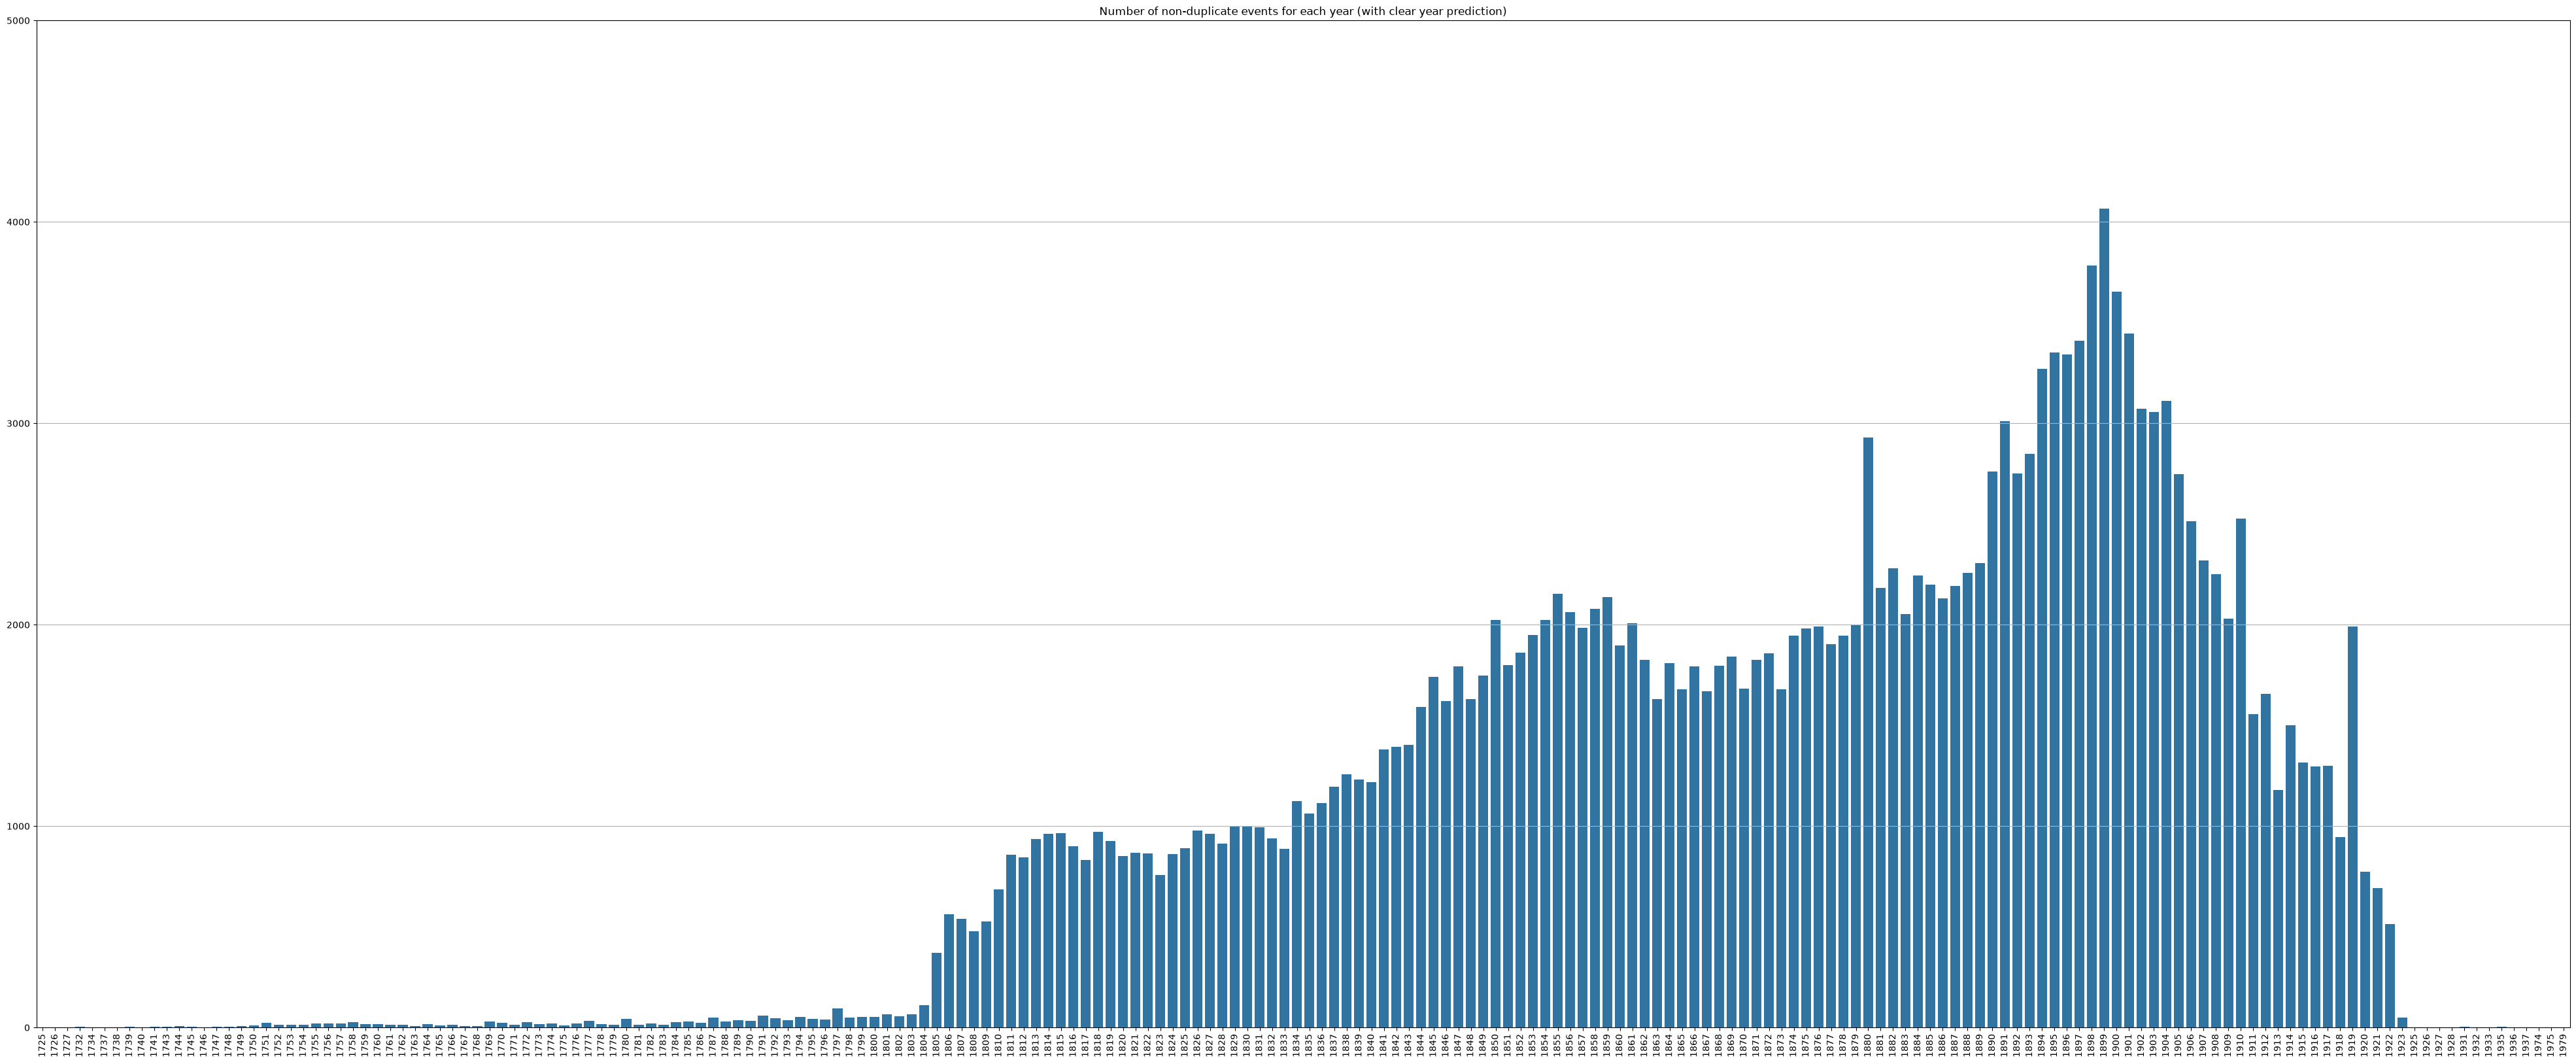

In [48]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["all_valid_year"].items()]),
    y=tuple([x[1] for x in year_counts["all_valid_year"].items()]),
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["all_valid_year"].keys()), rotation=90)

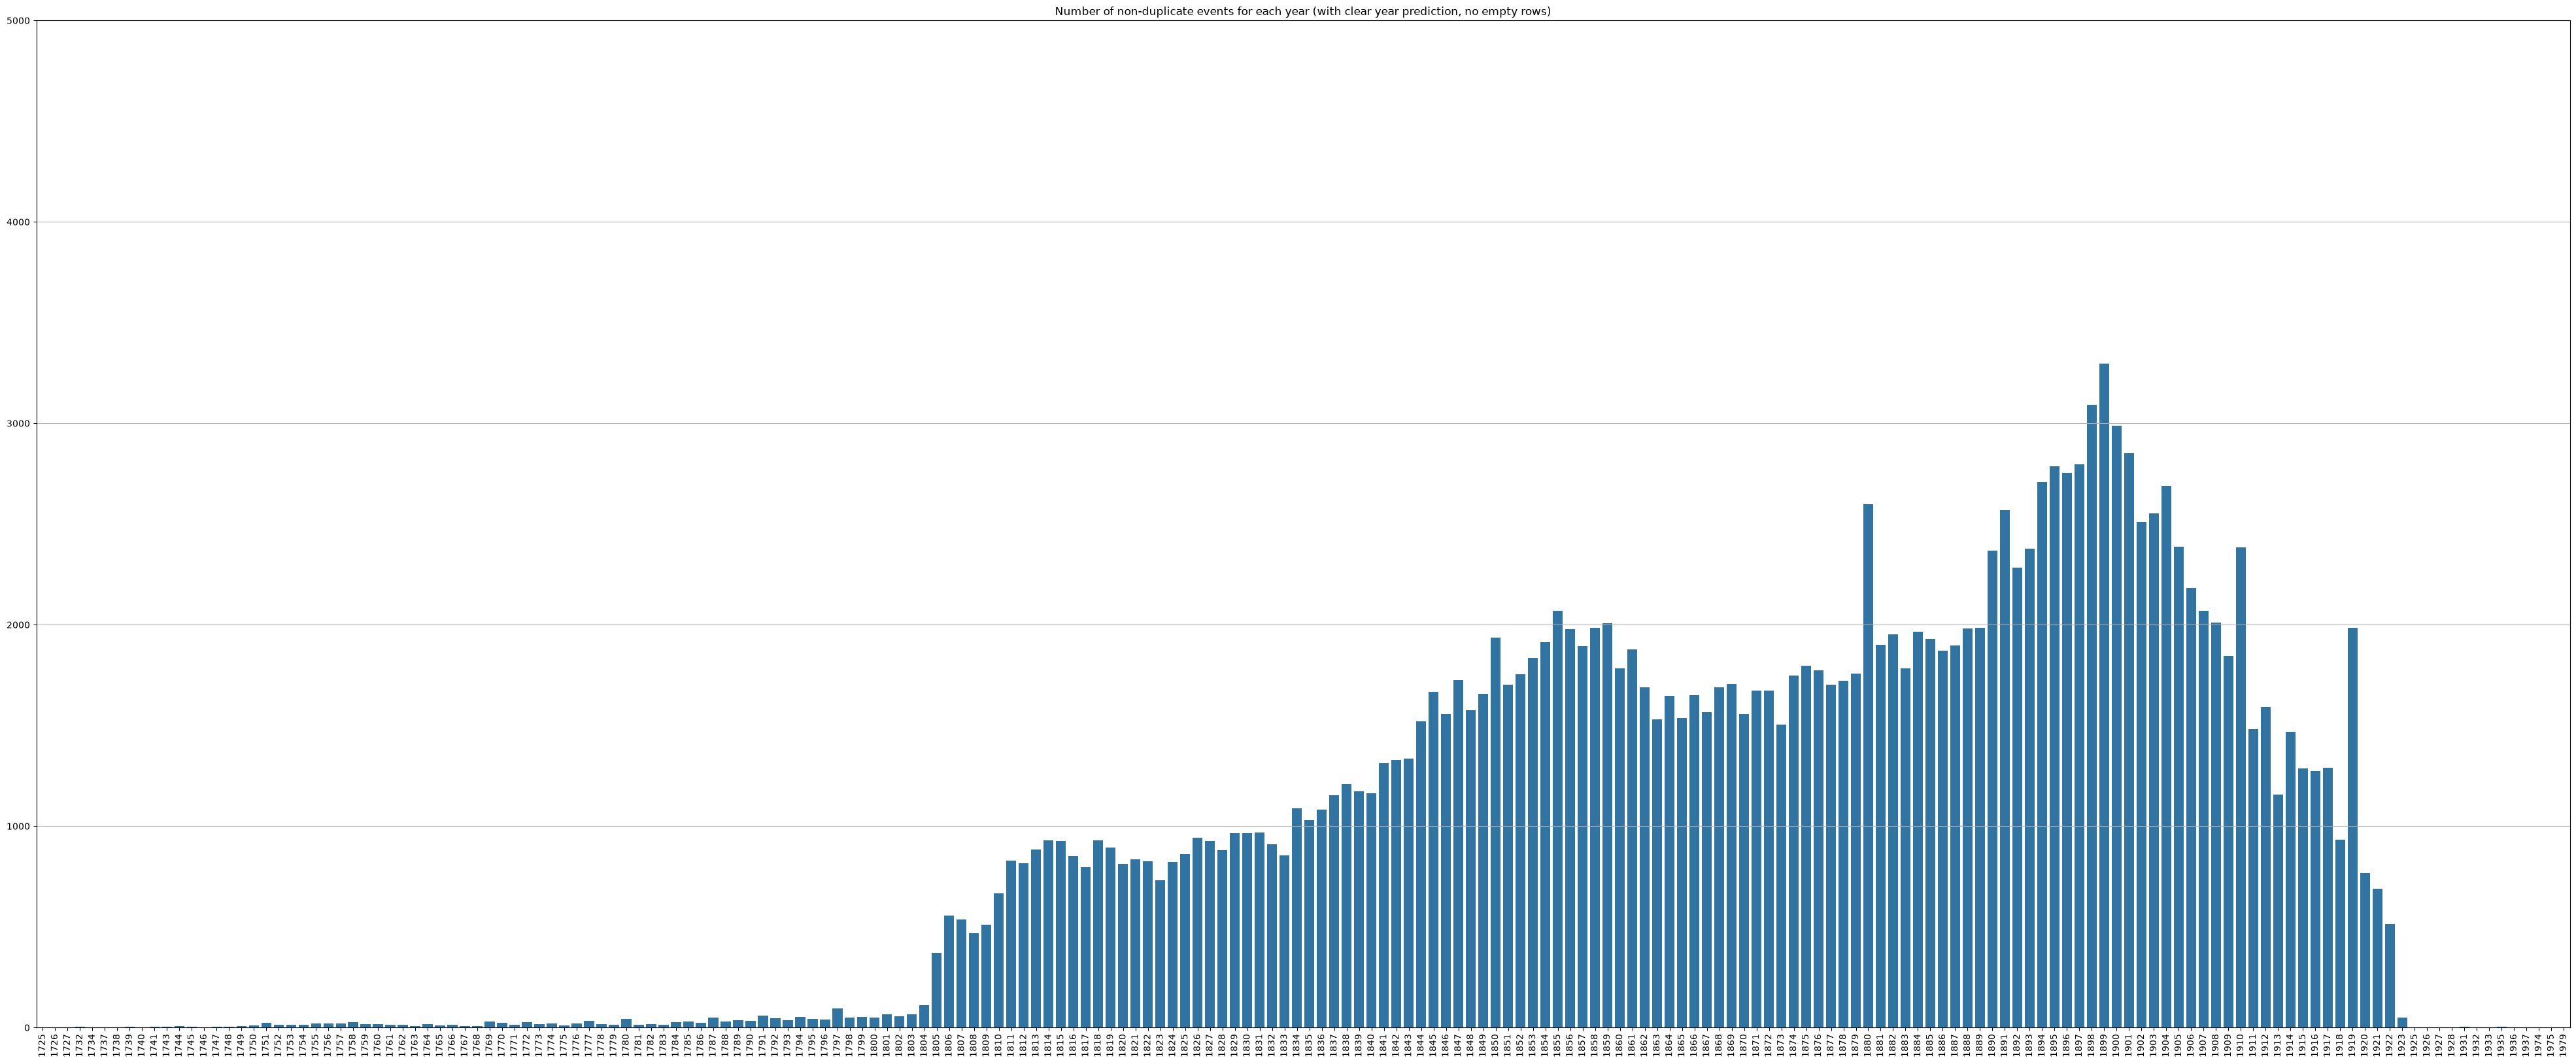

In [49]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup"].keys()), rotation=90)

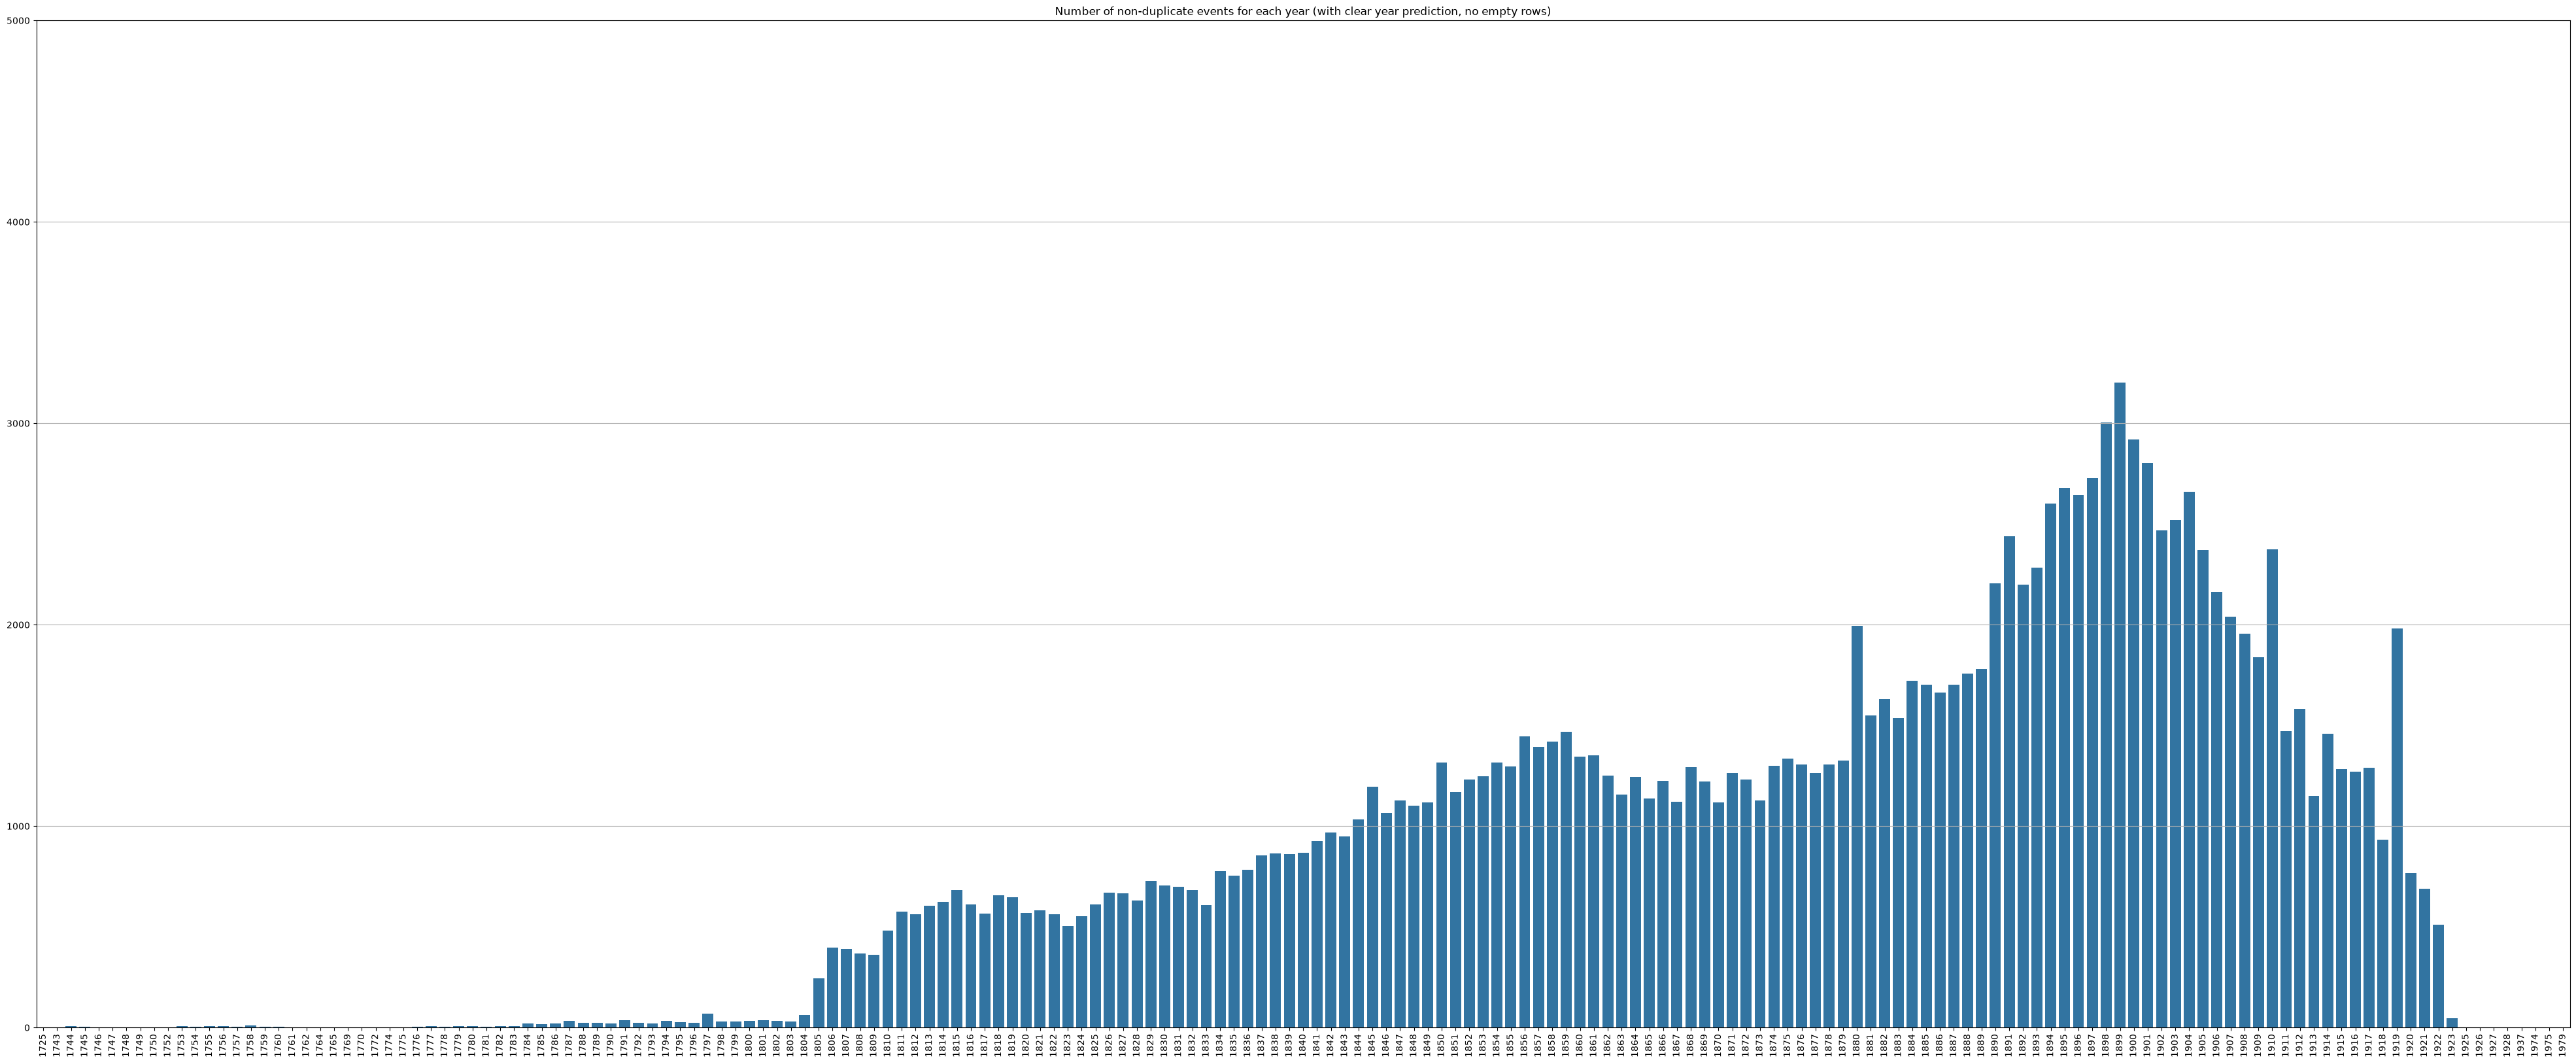

In [50]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup_clear"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup_clear"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup_clear"].keys()), rotation=90)

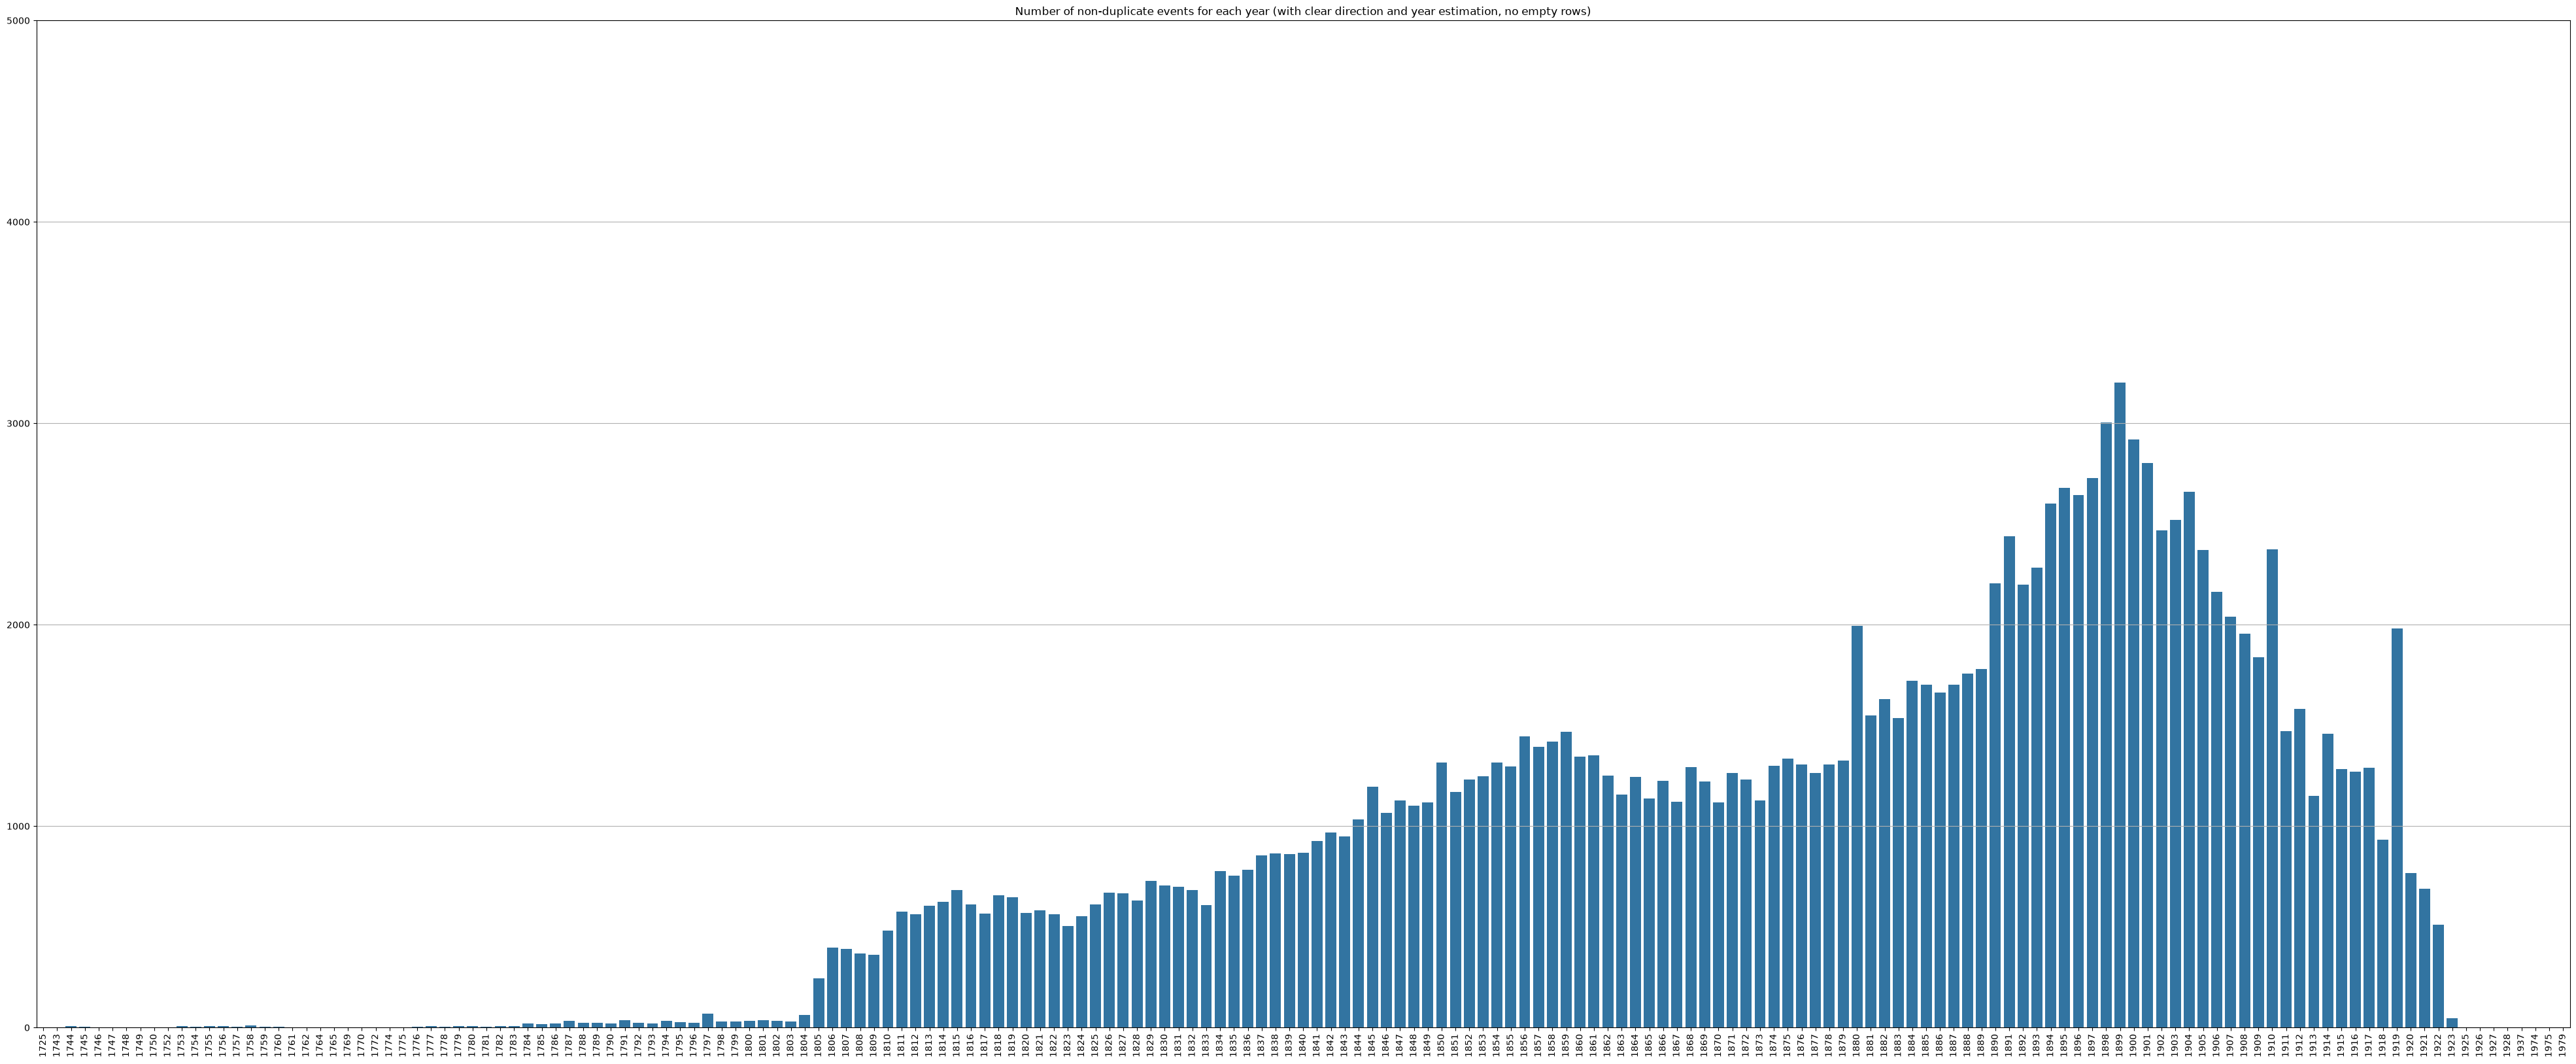

In [51]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup_clear_info"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup_clear_info"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup_clear_info"].keys()), rotation=90)

In [52]:
print(
    f"Pages in total: {counts['total']}",
    f"Pages with fewer than {MIN_INFO_ROWS} informative rows: {counts['total'] - counts['total_info']}",
    f"Total non-duplicate pages: {counts['non_dup']}",
    f"At least {counts['total'] - counts['non_dup']} duplicate pages.",
    f"Total non-duplicate pages with valid year: {sum(year_counts['non_dup'].values())}",
    f"Total non-duplicate pages with clear direction and valid year: {counts['non_dup_clear']}",
    f"At least {round(100 * counts['non_dup_clear'] / counts['non_dup'])}% of non-duplicate pages have unclear direction or year.",
    f"--- Pages with at least {MIN_INFO_ROWS} informative rows ---",
    f"Pages in total: {counts['total_info']}",
    f"Total non-duplicate pages: {counts['non_dup_info']}",
    f"At least {counts['total_info'] - counts['non_dup_info']} duplicate pages.",
    f"Total non-duplicate pages with valid year: {sum(year_counts['non_dup_info'].values())}",
    f"Total non-duplicate pages with clear direction and valid year: {counts['non_dup_clear_info']}",
    f"At least {round(100 * counts['non_dup_clear_info'] / counts['non_dup_info'])}% of non-duplicate pages have unclear direction or year.",
    sep="\n",
)

Pages in total: 283020
Pages with fewer than 0 informative rows: 0
Total non-duplicate pages: 257446
At least 25574 duplicate pages.
Total non-duplicate pages with valid year: 187088
Total non-duplicate pages with clear direction and valid year: 154392
At least 60% of non-duplicate pages have unclear direction or year.
--- Pages with at least 0 informative rows ---
Pages in total: 283020
Total non-duplicate pages: 257446
At least 25574 duplicate pages.
Total non-duplicate pages with valid year: 187088
Total non-duplicate pages with clear direction and valid year: 154392
At least 60% of non-duplicate pages have unclear direction or year.


Results from previous:
```text 
Pages in total: 283020
Pages with fewer than 0 informative rows: 0
Total non-duplicate pages: 256410
At least 26610 duplicate pages.
Total non-duplicate pages with valid year: 187125
Total non-duplicate pages with clear direction and valid year: 154667
At least 60% of non-duplicate pages have unclear direction or year.
--- Pages with at least 0 informative rows ---
Pages in total: 283020
Total non-duplicate pages: 256410
At least 26610 duplicate pages.
Total non-duplicate pages with valid year: 187125
Total non-duplicate pages with clear direction and valid year: 154667
At least 60% of non-duplicate pages have unclear direction or year.
```

In [71]:
direction_counter = {
    "in": 0,
    "out": 0,
    "?": 0,
    "both": 0,
    "abroad": 0
}

for page in page_records.values():
    direction_counter[page["in_out"]] += 1

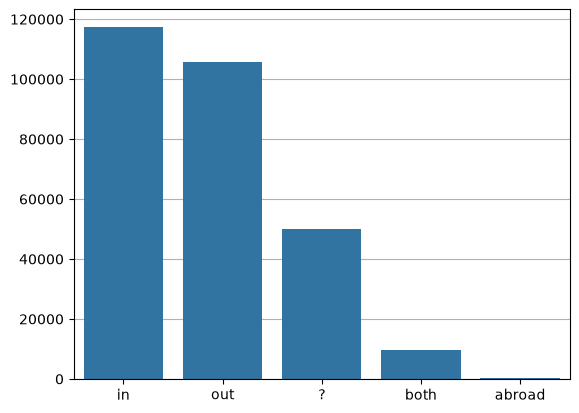

In [79]:
ax = sns.barplot(direction_counter)
ax.grid(axis="y")
ax.set_axisbelow(True)

In [74]:
direction_counter

{'in': 117416, 'out': 105853, '?': 49935, 'both': 9549, 'abroad': 267}